In [1]:
import sqlite3
import pandas as pd
import numpy as np

conn = sqlite3.connect('../data/database.sqlite')

matches = pd.read_sql("SELECT * FROM Match", conn)
print(matches.shape)
matches.head()

(25979, 115)


,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,...,4.00,1.65,3.40,4.50,1.78,3.25,4.00,1.73,3.40,4.20
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,...,3.80,2.00,3.25,3.25,1.85,3.25,3.75,1.91,3.25,3.60
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,...,2.50,2.35,3.25,2.65,2.50,3.20,2.50,2.30,3.20,2.75
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,...,7.50,1.45,3.75,6.50,1.50,3.75,5.50,1.44,3.75,6.50
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,...,1.73,4.50,3.40,1.65,4.50,3.50,1.65,4.75,3.30,1.67


In [2]:
leagues = pd.read_sql("SELECT id, name FROM League", conn)
teams = pd.read_sql("SELECT team_api_id, team_long_name FROM Team", conn)

print(leagues)
print(teams.head())

       id                      name
0       1    Belgium Jupiler League
1    1729    England Premier League
2    4769            France Ligue 1
3    7809     Germany 1. Bundesliga
4   10257             Italy Serie A
5   13274    Netherlands Eredivisie
6   15722        Poland Ekstraklasa
7   17642  Portugal Liga ZON Sagres
8   19694   Scotland Premier League
9   21518           Spain LIGA BBVA
10  24558  Switzerland Super League
   team_api_id     team_long_name
0         9987           KRC Genk
1         9993       Beerschot AC
2        10000   SV Zulte-Waregem
3         9994   Sporting Lokeren
4         9984  KSV Cercle Brugge


In [3]:
df = matches[[
    'id', 'league_id', 'season', 'date',
    'home_team_api_id', 'away_team_api_id',
    'home_team_goal', 'away_team_goal',
    'B365H', 'B365D', 'B365A'
]].copy()

print(df.shape)
df.head()

(25979, 11)


,id,league_id,season,date,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal,B365H,B365D,B365A
0,1,1,2008/2009,2008-08-17 00:00:00,9987,9993,1,1,1.73,3.40,5.00
1,2,1,2008/2009,2008-08-16 00:00:00,10000,9994,0,0,1.95,3.20,3.60
2,3,1,2008/2009,2008-08-16 00:00:00,9984,8635,0,3,2.38,3.30,2.75
3,4,1,2008/2009,2008-08-17 00:00:00,9991,9998,5,0,1.44,3.75,7.50
4,5,1,2008/2009,2008-08-16 00:00:00,7947,9985,1,3,5.00,3.50,1.65


In [4]:
print(df.isnull().sum())
print(f"\nTotal rows: {len(df)}")

id                     0
league_id              0
season                 0
date                   0
home_team_api_id       0
away_team_api_id       0
home_team_goal         0
away_team_goal         0
B365H               3387
B365D               3387
B365A               3387
dtype: int64

Total rows: 25979


In [5]:
df = df.dropna(subset=['B365H', 'B365D', 'B365A'])
print(f"Rows after cleaning: {len(df)}")

Rows after cleaning: 22592


In [6]:
df['date'] = pd.to_datetime(df['date'])

np.random.seed(42)
df['days_until_match'] = np.random.randint(1, 61, size=len(df))

df[['date', 'days_until_match']].head()

,date,days_until_match
0,2008-08-17,39
1,2008-08-16,52
2,2008-08-16,29
3,2008-08-17,15
4,2008-08-16,43


In [7]:
league_map = dict(zip(leagues['id'], leagues['name']))
df['league_name'] = df['league_id'].map(league_map)

top_leagues = [
    'England Premier League', 'Spain LIGA BBVA',
    'Italy Serie A', 'Germany 1. Bundesliga', 'France Ligue 1'
]

df['league_tier'] = df['league_name'].apply(lambda x: 1.5 if x in top_leagues else 1.0)

print(df['league_name'].value_counts())
df[['league_name', 'league_tier']].head()

league_name
England Premier League      3040
Spain LIGA BBVA             3039
France Ligue 1              3036
Italy Serie A               3011
Germany 1. Bundesliga       2447
Netherlands Eredivisie      2445
Portugal Liga ZON Sagres    2044
Scotland Premier League     1824
Belgium Jupiler League      1706
Name: count, dtype: int64


,league_name,league_tier
0,Belgium Jupiler League,1.0
1,Belgium Jupiler League,1.0
2,Belgium Jupiler League,1.0
3,Belgium Jupiler League,1.0
4,Belgium Jupiler League,1.0


In [8]:
df['odds_spread'] = df[['B365H', 'B365D', 'B365A']].std(axis=1)
df['competitiveness'] = 1 / (1 + df['odds_spread'])

df[['B365H', 'B365D', 'B365A', 'odds_spread', 'competitiveness']].head()

,B365H,B365D,B365A,odds_spread,competitiveness
0,1.73,3.40,5.00,1.635125,0.379489
1,1.95,3.20,3.60,0.860717,0.537427
2,2.38,3.30,2.75,0.462925,0.683562
3,1.44,3.75,7.50,3.058382,0.246404
4,5.00,3.50,1.65,1.678044,0.373407


In [9]:
df['match_importance_score'] = (df['league_tier'] * 2) + (df['competitiveness'] * 1)

df['match_importance_score'].describe()

count    22592.000000
mean         3.110192
std          0.520273
min          2.064982
25%          2.600300
50%          3.288290
75%          3.548820
max          3.949744
Name: match_importance_score, dtype: float64

In [10]:
df['total_goals'] = df['home_team_goal'] + df['away_team_goal']
df['goals_factor'] = df['total_goals'].clip(upper=6) / 6

df[['total_goals', 'goals_factor']].describe()

,total_goals,goals_factor
count,22592.000000,22592.000000
mean,2.715165,0.447164
std,1.676957,0.265564
min,0.000000,0.000000
25%,2.000000,0.333333
50%,3.000000,0.500000
75%,4.000000,0.666667
max,12.000000,1.000000


In [11]:
np.random.seed(123)
df['current_occupancy_rate'] = np.random.uniform(0, 1, size=len(df))

df['current_occupancy_rate'].describe()

count    22592.000000
mean         0.500200
std          0.287772
min          0.000068
25%          0.248006
50%          0.504693
75%          0.748494
max          0.999890
Name: current_occupancy_rate, dtype: float64

In [22]:
base_signal = (
    (df['match_importance_score'] - df['match_importance_score'].min()) /
    (df['match_importance_score'].max() - df['match_importance_score'].min())
) * 0.35 + (df['goals_factor'] * 0.10) + (df['current_occupancy_rate'] * 0.55)

noise = np.random.normal(0, 0.05, size=len(df))
df['demand_score'] = (base_signal + noise).clip(0, 1)

df['demand_score'].describe()

count    22592.000000
mean         0.513739
std          0.191807
min          0.000000
25%          0.374147
50%          0.515325
75%          0.658317
max          1.000000
Name: demand_score, dtype: float64

In [23]:
feature_columns = [
    'days_until_match',
    'match_importance_score',
    'league_tier',
    'current_occupancy_rate',
]

X = df[feature_columns]
y = df['demand_score']

print(X.shape, y.shape)
X.head()

(22592, 4) (22592,)


,days_until_match,match_importance_score,league_tier,current_occupancy_rate
0,39,2.379489,1.0,0.696469
1,52,2.537427,1.0,0.286139
2,29,2.683562,1.0,0.226851
3,15,2.246404,1.0,0.551315
4,43,2.373407,1.0,0.719469


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")

Training set: (18073, 4)
Test set: (4519, 4)


In [25]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
print("Model trained!")

Model trained!


In [26]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    'actual': y_test.values[:10],
    'predicted': y_pred[:10]
})
print(comparison)

     actual  predicted
0  0.134352   0.117317
1  0.193112   0.269889
2  0.356002   0.391422
3  0.495714   0.451006
4  0.819643   0.812492
5  0.455504   0.531623
6  0.181914   0.215682
7  0.296627   0.264991
8  0.801297   0.816540
9  0.573003   0.542042


In [27]:
from sklearn.metrics import mean_squared_error, r2_score

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"RMSE: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

RMSE: 0.0579
R² Score: 0.9076


In [28]:
importance_df = pd.DataFrame({
    'feature': feature_columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

print(importance_df)

                  feature  importance
3  current_occupancy_rate    0.733867
1  match_importance_score    0.237820
2             league_tier    0.021290
0        days_until_match    0.007023


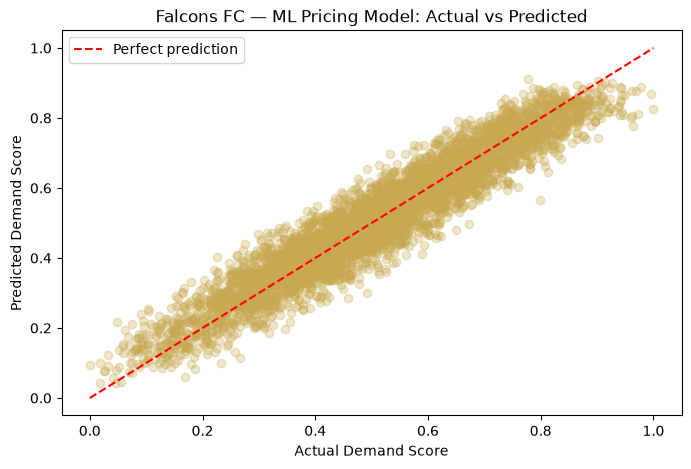

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.3, color='#c8a951')
plt.plot([0, 1], [0, 1], 'r--', label='Perfect prediction')
plt.xlabel('Actual Demand Score')
plt.ylabel('Predicted Demand Score')
plt.title('Falcons FC — ML Pricing Model: Actual vs Predicted')
plt.legend()
plt.savefig('../models/prediction_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

In [30]:
import joblib

joblib.dump(model, '../models/dynamic_pricing_model.pkl')
joblib.dump(feature_columns, '../models/feature_columns.pkl')
print("Model and features saved!")

Model and features saved!


In [31]:
test_low = pd.DataFrame([{
    'days_until_match': 5,
    'match_importance_score': 3.0,
    'league_tier': 1.0,
    'current_occupancy_rate': 0.10,
}])[feature_columns]

test_high = pd.DataFrame([{
    'days_until_match': 5,
    'match_importance_score': 3.0,
    'league_tier': 1.0,
    'current_occupancy_rate': 0.99,
}])[feature_columns]

print("10% occupancy:", model.predict(test_low)[0])
print("99% occupancy:", model.predict(test_high)[0])

10% occupancy: 0.3107473401846397
99% occupancy: 0.7457412014691114
